# Análisis exploratorio de datos EDA


## Setup y Conexión a BigQuery

In [3]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from google.cloud import bigquery

# Estilo visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

load_dotenv("../.env")
credentials_path = os.getenv("GOOGLE_APPLICATION_CREDENTIALS")
if credentials_path:
    if not os.path.isabs(credentials_path):
        os.environ["GOOGLE_APPLICATION_CREDENTIALS"] = os.path.abspath(
            os.path.join("..", credentials_path)
        )

PROJECT_ID = os.getenv("GCP_PROJECT_ID")
DATASET_ID = os.getenv("GCP_DATASET_ID")
TABLE_NAME = "telco_churn_features"

client = bigquery.Client(project=PROJECT_ID)
print(f" Conectado a BigQuery: {PROJECT_ID}.{DATASET_ID}.{TABLE_NAME}")

 Conectado a BigQuery: portafolio-511501.CUSTOMER_CHURN.telco_churn_features


## Extracción de datos de BQ a DataFrame

In [4]:
query = f"""
SELECT * 
FROM `{PROJECT_ID}.{DATASET_ID}.{TABLE_NAME}`
"""

df = client.query(query).to_dataframe()
print(f"Shape del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head(3)

Shape del dataset: 7043 filas x 33 columnas


,customer_id,gender,senior_citizen,partner,dependents,tenure_months,country,state,city,zip_code,...,payment_method,monthly_charges,total_charges,cltv,churn_target,monthly_to_avg_charge_ratio,total_vas_services,is_month_to_month,high_risk_fiber_no_support,tenure_cohort
0,1932-UEDCX,Male,1,Yes,No,33,United States,California,Manchester,95459,...,Bank transfer (automatic),100.60,3270.25,3669.0,0,1.0152,3,1,1,25-48_months
1,8510-AWCXC,Female,1,No,No,13,United States,California,Novato,94945,...,Electronic check,100.80,1308.10,3269.0,1,1.0018,3,1,1,13-24_months
2,5293-WXJAK,Female,1,Yes,No,11,United States,California,San Jose,95135,...,Bank transfer (automatic),104.05,1133.65,4553.0,1,1.0096,4,1,0,0-12_months


### Auditoría de Completitud y Valores Faltantes

In [12]:
null_summary = pd.DataFrame({
    'Tipo': df.dtypes,
    'Valores_Nulos': df.isnull().sum(),
    'Porcentaje_Nulos': (df.isnull().sum() / len(df)) * 100,
    'Valores_Unicos': df.nunique()
})

# Filtrar o mostrar columnas con nulos o resumen general
print(f"Total registros analizados: {len(df)}")
print(f"Columnas con nulos detectados: {(null_summary['Valores_Nulos'] > 0).sum()}")

null_summary[null_summary['Valores_Nulos'] > 0]

Total registros analizados: 7043
Columnas con nulos detectados: 0


,Tipo,Valores_Nulos,Porcentaje_Nulos,Valores_Unicos


Se confirma que la capa `create_features` en BigQuery consolidó una matriz 100% íntegra sin valores nulos en el conjunto histórico analizado.

## Auditoría de Calidad y Target Churn

In [5]:
churn_counts = df['churn_target'].value_counts(normalize=True) * 100
prop_churn, prop_no_churn = churn_counts[1], churn_counts[0]

churn, no_churn,  = df['churn_target'].value_counts()[1], df['churn_target'].value_counts()[0]

print("--- DISTRIBUCIÓN DE CHURN ---")
print(
    f"No Churn (0): {prop_no_churn:.2f}% ({no_churn:,} clientes)"
)
print(
    f"Churn (1):    {prop_churn:.2f}% ({churn:,} clientes)"
)

# 2. Impacto Financiero Directo en MRR
mrr_lost = df[df["churn_target"] == 1]["monthly_charges"].sum()
mrr_total = df["monthly_charges"].sum()
print("\n--- IMPACTO FINANCIERO (MRR) ---")
print(f"MRR Total en Cartera:  ${mrr_total:,.2f} USD")
print(
    f"MRR Perdido por Churn: ${mrr_lost:,.2f} USD ({(mrr_lost/mrr_total)*100:.2f}% de la facturación mensual)"
)

--- DISTRIBUCIÓN DE CHURN ---
No Churn (0): 73.46% (5,174 clientes)
Churn (1):    26.54% (1,869 clientes)

--- IMPACTO FINANCIERO (MRR) ---
MRR Total en Cartera:  $456,116.60 USD
MRR Perdido por Churn: $139,130.85 USD (30.50% de la facturación mensual)


### Diagnóstico de Cartera e Impacto Financiero

1. La primera observación nos permite analizar un desbalance modelado de clases, la tasa de churn de la cartera es del **26.54%** (1,869 clientes fugados) frente a **73.46%** (5,174 clientes activos). Un modelo de clasificación simple que prediga siempre clase 0 obtendría un 73.46% de *Accuracy* sin detectar a ningún cliente en riesgo. Por lo tanto, la métrica principal de optimización debe ser **PR-AUC (Precision-Recall AUC)**, **ROC-AUC** o **F1-Score ponderado**, para esto se requiere ponderación de pesos (`class_weight='balanced'`) en los modelos supervisados que se utilizarán.

2. El 26.54% de los clientes representa el **30.50% del Monthly Recurring Revenue (MRR)** total ($139,130.85 USD mensuales de pérdida). Esto quiere decir que Los clientes que cancelan el servicio tienen un gasto promedio mensual superior al cliente promedio retenido ($74.44 USD/mes en churners vs. $61.27 USD/mes en no churners) lo cual impacta al negocio y genera un ARPU vulnerable. Entonces, la fuga impacta por dos lados, tanto al volumen de clientes de la empresa y al mismo tiempo está impactando fuertemente los segmentos de mayor facturación.

## Visualización de Hipótesis de Negocio

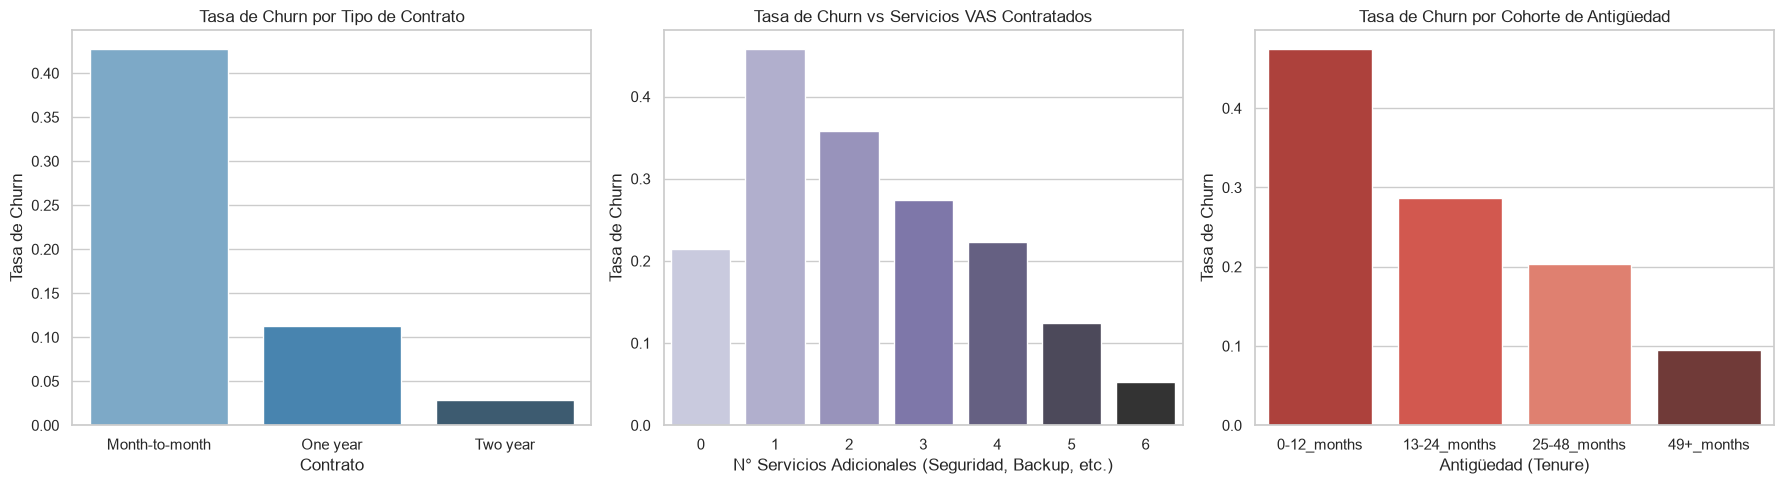

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# A. Churn según Contrato Mes a Mes
sns.barplot(
    data=df,
    x="contract",
    y="churn_target",
    ax=axes[0],
    estimator=np.mean,
    errorbar=None,
    palette="Blues_d",
    hue='contract',
    legend=False
)
axes[0].set_title("Tasa de Churn por Tipo de Contrato")
axes[0].set_ylabel("Tasa de Churn")
axes[0].set_xlabel("Contrato")

# B. Churn según Conteo de Servicios de Valor Agregado (VAS)
sns.barplot(
    data=df,
    x="total_vas_services",
    y="churn_target",
    ax=axes[1],
    estimator=np.mean,
    errorbar=None,
    palette="Purples_d",
    hue='total_vas_services',
    legend=False
)
axes[1].set_title("Tasa de Churn vs Servicios VAS Contratados")
axes[1].set_ylabel("Tasa de Churn")
axes[1].set_xlabel("N° Servicios Adicionales (Seguridad, Backup, etc.)")

# C. Churn por Cohorte de Antigüedad
cohort_order = ["0-12_months", "13-24_months", "25-48_months", "49+_months"]
sns.barplot(
    data=df,
    x="tenure_cohort",
    y="churn_target",
    order=cohort_order,
    ax=axes[2],
    estimator=np.mean,
    errorbar=None,
    palette="Reds_d",
    hue='tenure_cohort',
    legend=False
)
axes[2].set_title("Tasa de Churn por Cohorte de Antigüedad")
axes[2].set_ylabel("Tasa de Churn")
axes[2].set_xlabel("Antigüedad (Tenure)")

plt.tight_layout()
plt.show()

### Conclusiones Clave de las Hipótesis de Negocio

* Los contratos **Month-to-month** concentran una tasa de fuga cercana al **43%**, mientras que contratos a uno o dos años reducen el churn a niveles inferiores al **11%** y **3%** respectivamente.
  * La acción recomendada identificada para este tipo de clientes **Month-to-month** es generar incentivos de retención que se enfoquen en migrar clientes mensuales a planes anuales con descuentos o beneficios acumulativos.

* Existe una correlación inversa moderada entre el número de servicios adicionales (`total_vas_services`) y la tasa de cancelación: clientes con 0 servicios adicionales tienen un churn de un **21%** y los clientes con solo 1 servicio adicional tienen un churn de **45.76%**, mientras que a partir de 3 o más servicios la probabilidad vuelve a caer por debajo del **27%**.
  * El cross-selling de seguridad (`online_security`) y soporte técnico (`tech_support`) funciona como ancla operativa que eleva los costos de cambio (*switching costs*) para el usuario.

* La cohorte `0-12_months` registra casi un **48% de tasa de churn**, disminuyendo progresivamente hasta menos del **10%** en clientes con más de 4 años de permanencia.
  * El ciclo de vida del cliente es más frágil durante el proceso de onboarding y los primeros ciclos de facturación; un programa de acompañamiento temprano en los primeros 90 días tendría el mayor potencial de retorno de inversión (ROI).

### Cruce Tecnológico y Matriz de Correlación

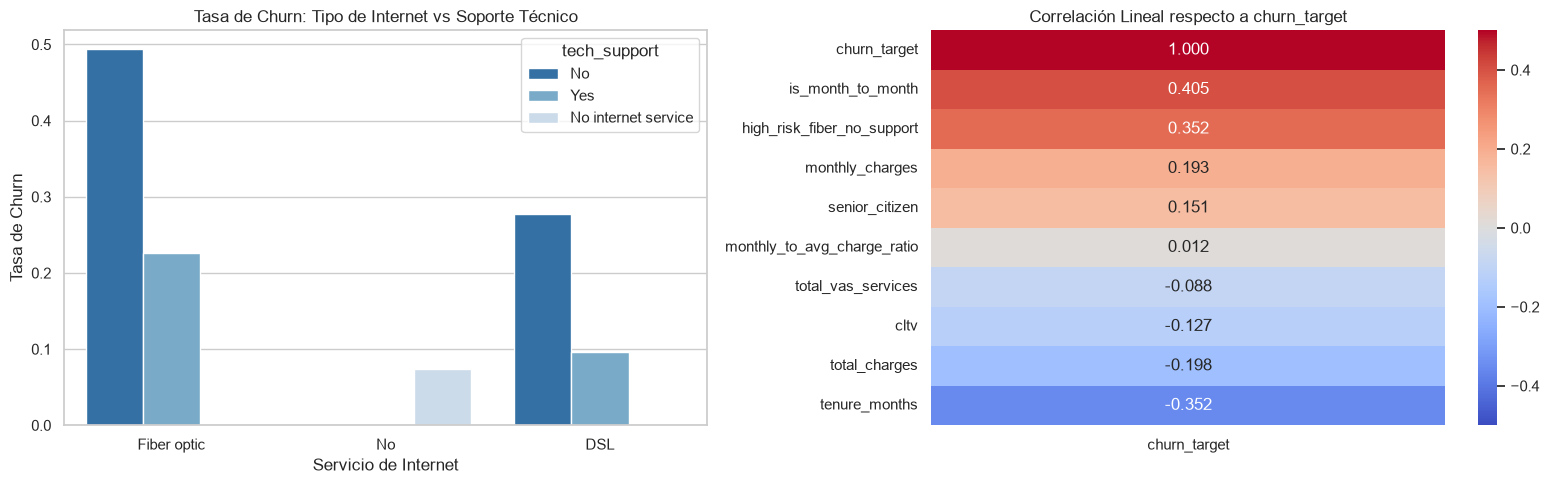

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Churn según Tipo de Internet y Soporte Técnico
sns.barplot(
    data=df,
    x="internet_service",
    y="churn_target",
    hue="tech_support",
    ax=axes[0],
    palette="Blues_r",
    errorbar=None
)
axes[0].set_title("Tasa de Churn: Tipo de Internet vs Soporte Técnico")
axes[0].set_ylabel("Tasa de Churn")
axes[0].set_xlabel("Servicio de Internet")

# 2. Matriz de Correlación de Variables Numéricas con Churn
numeric_cols = [
    "senior_citizen","tenure_months", "monthly_charges", "total_charges", 
    "cltv", "monthly_to_avg_charge_ratio", "total_vas_services", 
    "is_month_to_month", "high_risk_fiber_no_support", "churn_target"
]

corr_matrix = df[numeric_cols].corr()
sns.heatmap(
    corr_matrix[["churn_target"]].sort_values(by="churn_target", ascending=False),
    annot=True,
    cmap="coolwarm",
    vmin=-0.5,
    vmax=0.5,
    fmt=".3f",
    ax=axes[1]
)
axes[1].set_title("Correlación Lineal respecto a churn_target")

plt.tight_layout()
plt.show()

### Conclusiones del Cruce Tecnológico y Análisis de Correlación

1. La Fibra Óptica sin Soporte Técnico es el Mayor Foco de Fuga, podemos observar en el gráfico "Tasa de Churn: Tipo de Internet vs Soporte Técnico" que los clientes con **Fiber Optic sin Tech Support** alcanzan una tasa de churn cercana al **50% (0.49)**. Al agregar soporte técnico al mismo servicio de fibra, la tasa de fuga se reduce a menos de la mitad (**~22%**).

2. En tecnología **DSL**, la tasa de churn es considerablemente menor (~28% sin soporte y ~10% con soporte). Esto nos indica que la fibra óptica tiene un cargo mensual más alto y expectativas de servicio más exigentes. Cuando falla y el cliente no tiene asistencia resolutiva, el incentivo económico para migrar a la competencia es inmediato.

3. La variable creada `high_risk_fiber_no_support` se posiciona como el **segundo predictor positivo más fuerte (+0.352)**, solo por detrás de tener contrato mes a mes (`is_month_to_month` con **+0.405**). Esto demuestra que la ingeniería de características en BigQuery capturó exitosamente una vulnerabilidad estructural de la operación.

4. **Antigüedad (`tenure_months` = -0.352)** y **Gasto acumulado (`total_charges` = -0.198)** presentan correlación negativa fuerte con la fuga. A mayor tiempo de permanencia, mayor es la inercia y menor la probabilidad de abandono. `monthly_charges` tiene correlación positiva (+0.193): los clientes con facturas más altas son los más propensos a evaluar ofertas de la competencia.

5. Finalmente `monthly_to_avg_charge_ratio` presenta una correlación lineal prácticamente nula (+0.012), indicando que las variaciones puntuales de facturación en este dataset no explican la fuga de forma directa.